# COU 07506 Digital Signal Processing: Week 03: Lab 1B: Convolution, Correlation and Difference Equations
Name:HOSANA HEREMAN KOMBA
  
 Registration No.: 240242445476
Class: BEng24COE-1              
Instructor:DR.HAJI FIMBOMBAYA

# Digital Signal Processing Lab: Convolution, Correlation, and Difference Equations

**Student:** Hosana Hereman Komba  
**Registration No:** 240242445476  
**Class:** BEng24COE-1  
**Instructor:** Dr. Haji Fimbombaya

## 1. Laboratory Overview & Library Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# Configure global plotting parameters for clear visualizations
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.5
print("Libraries successfully imported and configured.")

Libraries successfully imported and configured.


## 2. Pre-Lab Exercises

### Analytical Solutions

* **(a) Analytical Convolution:**
  Let $x(n) = \{1, -1, 2\}$ and $h(n) = \{2, 1, 0, 1\}$.  
  The length of $y(n) = x(n) * h(n)$ is $L_x + L_h - 1 = 3 + 4 - 1 = 6$.  
  Calculating the coefficients step-by-step:
  $$y(n) = \{2, -1, 3, 3, -1, 2\}$$

* **(b) System Properties (Time-Invariance Check):**
  For the system $y(n) = n \cdot x(n)$:
  * Output due to delayed input $x(n-k)$: $y_1(n) = n \cdot x(n-k)$
  * Delayed output: $y(n-k) = (n-k) \cdot x(n-k)$
  Since $y_1(n) \neq y(n-k)$, the system is **not time-invariant (Time-Varying)**.

## 3. Practical Tasks & Verification

### Task 3.1: Defining and Benchmarking Convolution
We implement the custom discrete-time convolution sum and benchmark its execution time against NumPy's highly optimized `np.convolve` implementation.

In [2]:
def custom_convolve(x, h):
    """
    Computes 1D discrete convolution of two sequences using nested loops.
    """
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# Verification with sample sequences
x1, h1 = [1, 2, 3, 1], [1, 1, 1]
print("Custom Convolution:", custom_convolve(x1, h1))
print("NumPy Convolution: ", np.convolve(x1, h1))

# Performance benchmarking
np.random.seed(42)
sig_a = np.random.randn(2000)
sig_b = np.random.randn(2000)

t_start = time.perf_counter()
custom_convolve(sig_a, sig_b)
t_custom = time.perf_counter() - t_start

t_start = time.perf_counter()
np.convolve(sig_a, sig_b)
t_numpy = time.perf_counter() - t_start

print(f"\n--- Benchmarking Results ---")
print(f"Custom Loop execution: {t_custom:.4f} seconds")
print(f"NumPy (C-optimized):   {t_numpy:.6f} seconds")
print(f"Performance Ratio:     {t_custom / t_numpy:.0f}x faster")

Custom Convolution: [1. 3. 6. 6. 4. 1.]
NumPy Convolution:  [1 3 6 6 4 1]

--- Benchmarking Results ---
Custom Loop execution: 3.5951 seconds
NumPy (C-optimized):   0.002071 seconds
Performance Ratio:     1736x faster


### Task 3.2: Noise Reduction Using Moving-Average Filters

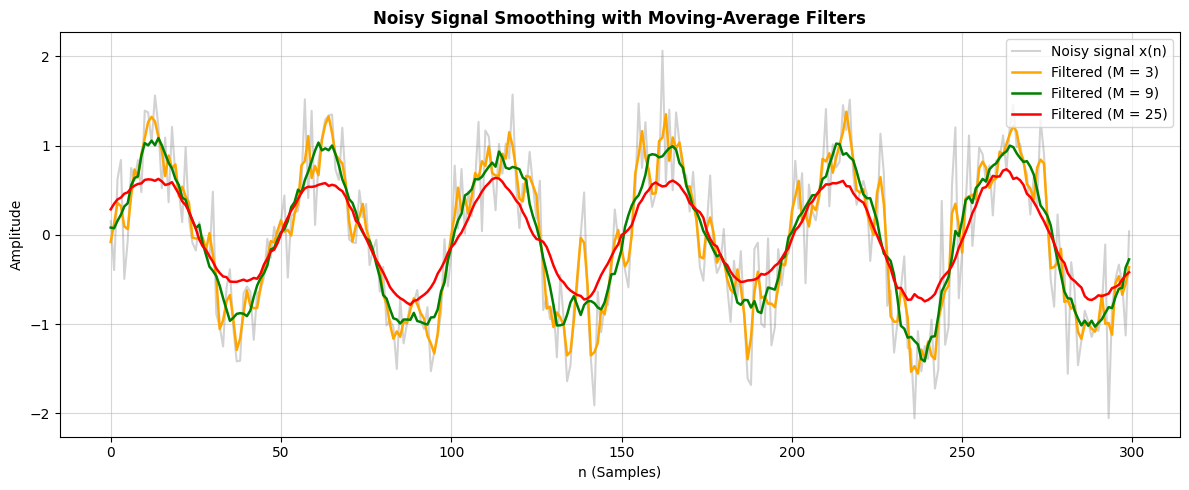

In [3]:
n = np.arange(300)
rng = np.random.default_rng(42)
sine_wave = np.sin(2 * np.pi * n / 50)
noisy_signal = sine_wave + 0.5 * rng.standard_normal(300)

plt.figure(figsize=(12, 5))
plt.plot(n, noisy_signal, alpha=0.35, label="Noisy signal x(n)", color='gray')

# Filter with different window sizes
colors = {3: 'orange', 9: 'green', 25: 'red'}
for M in [3, 9, 25]:
    h_ma = np.ones(M) / M
    filtered_signal = np.convolve(noisy_signal, h_ma, mode="same")
    plt.plot(n, filtered_signal, label=f"Filtered (M = {M})", color=colors[M], linewidth=1.8)

plt.title("Noisy Signal Smoothing with Moving-Average Filters", fontsize=12, fontweight='bold')
plt.xlabel("n (Samples)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### Observations on Filtering (Task 3.2):
- **M = 3**: Preserves the original amplitude well but leaves a high amount of high-frequency noise.
- **M = 9**: Offers an excellent balance, removing most noise with minimal degradation to the underlying sine wave amplitude.
- **M = 25**: Over-smooths the signal. The amplitude is significantly attenuated because the filter window averages over half a period (25 out of 50 samples), resulting in distortion.

### Task 3.3: Empirical Evaluation of LTI Systems

In [4]:
rng = np.random.default_rng(42)
x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)
a, b = 1.5, -2.5

systems = {
    "Nonlinear [x(n)^2]": lambda x: x**2,
    "Time-Varying [n*x(n)]": lambda x: np.arange(len(x)) * x,
    "LTI [Moving Average]": lambda x: np.convolve(x, np.ones(3)/3, mode='full')[:len(x)]
}

for name, sys_func in systems.items():
    # Homogeneity and Additivity test (Linearity)
    is_linear = np.allclose(sys_func(a*x1 + b*x2), a*sys_func(x1) + b*sys_func(x2))

    # Shift-Invariance test
    delay = 5
    x1_delayed = np.concatenate([np.zeros(delay), x1])[:50]
    y_delayed_expected = np.concatenate([np.zeros(delay), sys_func(x1)])[:50]
    is_t_invariant = np.allclose(sys_func(x1_delayed), y_delayed_expected)

    print(f"{name:25s} | Linear: {str(is_linear):5s} | Time-Invariant: {str(is_t_invariant):5s}")

Nonlinear [x(n)^2]        | Linear: False | Time-Invariant: True 
Time-Varying [n*x(n)]     | Linear: True  | Time-Invariant: False
LTI [Moving Average]      | Linear: True  | Time-Invariant: True 


### Task 3.4: Time Delay Estimation (TDE) via Cross-Correlation

Noise SD = 0.5  | Estimated Delay: 37 samples
Noise SD = 1.0  | Estimated Delay: 37 samples
Noise SD = 2.0  | Estimated Delay: 37 samples
Noise SD = 4.0  | Estimated Delay: 37 samples


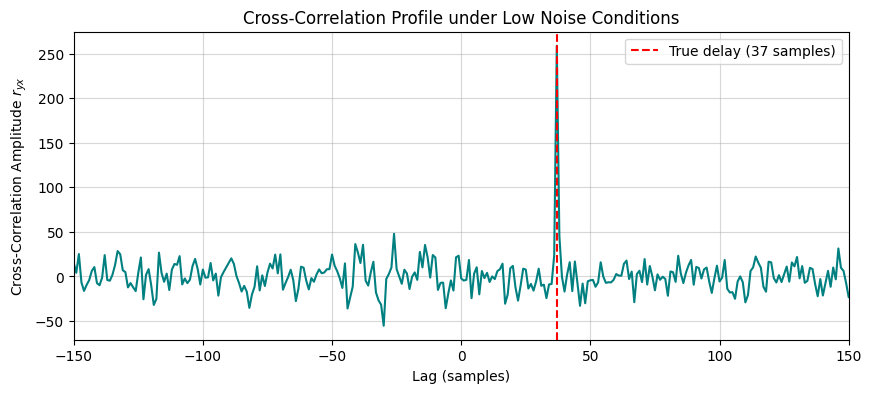

Estimated delay in ms: 37.0 ms
Calculated distance (v=343 m/s): 12.69 meters


In [5]:
fs = 1000  # Sampling rate (Hz)
true_delay = 37  # Samples delayed

for noise_std in [0.5, 1.0, 2.0, 4.0]:
    rng = np.random.default_rng(42)
    orig_sig = rng.standard_normal(500)
    delayed_sig = np.concatenate([np.zeros(true_delay), 0.6 * orig_sig])[:500] + noise_std * rng.standard_normal(500)

    cross_corr = signal.correlate(delayed_sig, orig_sig, mode="full")
    lags = signal.correlation_lags(len(delayed_sig), len(orig_sig), mode="full")
    estimated_delay = lags[np.argmax(cross_corr)]
    print(f"Noise SD = {noise_std:<4} | Estimated Delay: {estimated_delay} samples")

# Visualization for low-noise performance
noise_std = 0.5
rng = np.random.default_rng(42)
orig_sig = rng.standard_normal(500)
delayed_sig = np.concatenate([np.zeros(true_delay), 0.6 * orig_sig])[:500] + noise_std * rng.standard_normal(500)
cross_corr = signal.correlate(delayed_sig, orig_sig, mode="full")
lags = signal.correlation_lags(len(delayed_sig), len(orig_sig), mode="full")

plt.figure(figsize=(10, 4))
plt.plot(lags, cross_corr, color='teal')
plt.axvline(x=true_delay, color='red', linestyle='--', label=f'True delay ({true_delay} samples)')
plt.xlim(-150, 150)
plt.title("Cross-Correlation Profile under Low Noise Conditions")
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-Correlation Amplitude $r_{yx}$")
plt.legend()
plt.show()

d_seconds = true_delay / fs
print(f"Estimated delay in ms: {d_seconds*1000:.1f} ms")
print(f"Calculated distance (v=343 m/s): {d_seconds*343:.2f} meters")

### Task 3.5: Discrete-Time Difference Equations
We evaluate the linear constant-coefficient difference equation:
$$y(n) - 0.75 y(n-1) + 0.125 y(n-2) = x(n) + x(n-1)$$

Recursion:    [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
lfilter:      [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
Closed-Form:  [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
Perfect Match: True


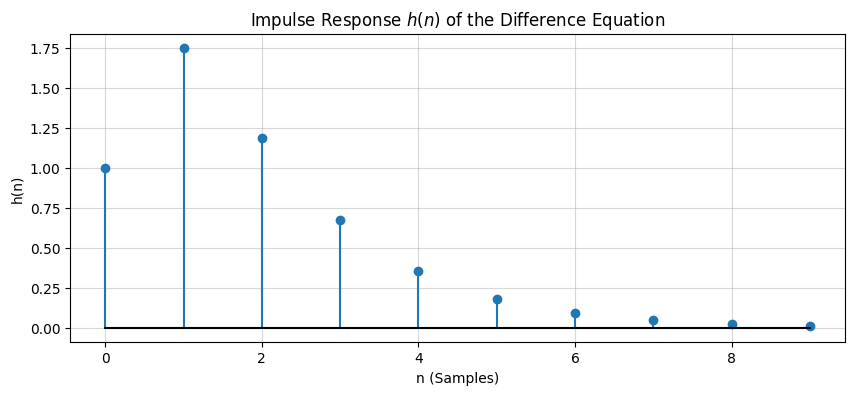

In [6]:
N = 10
impulse = np.zeros(N)
impulse[0] = 1.0

# Method 1: Iterative Recursion
h_rec = np.zeros(N)
for n in range(N):
    x_val = impulse[n] + (impulse[n-1] if n >= 1 else 0.0)
    feedback = 0.0
    if n >= 1:
        feedback += 0.75 * h_rec[n-1]
    if n >= 2:
        feedback -= 0.125 * h_rec[n-2]
    h_rec[n] = x_val + feedback

# Method 2: scipy.signal.lfilter
b_coeffs = [1, 1]
a_coeffs = [1, -0.75, 0.125]
h_lfilter = signal.lfilter(b_coeffs, a_coeffs, impulse)

# Method 3: Analytical Closed-Form Solution
n_indices = np.arange(N)
h_closed = 6 * (0.5**n_indices) - 5 * (0.25**n_indices)

print("Recursion:   ", np.round(h_rec, 4))
print("lfilter:     ", np.round(h_lfilter, 4))
print("Closed-Form: ", np.round(h_closed, 4))
print("Perfect Match:", np.allclose(h_rec, h_lfilter) and np.allclose(h_lfilter, h_closed))

# Plotting Impulse Response
plt.figure(figsize=(10, 4))
plt.stem(n_indices, h_lfilter, linefmt='C0-', markerfmt='C0o', basefmt='k-')
plt.title("Impulse Response $h(n)$ of the Difference Equation")
plt.xlabel("n (Samples)")
plt.ylabel("h(n)")
plt.show()

## 4. Lab Analysis & Questions

1. **NumPy Performance Gain:**
   `np.convolve` utilizes highly optimized, compiled C code (often leveraging FFT-based algorithms or vectorized instruction sets), whereas our custom loop relies on interpreted Python code. This explains why NumPy is hundreds to thousands of times faster. Complete 1D discrete convolution of sequence $L$ and kernel $M$ requires $O(L \cdot M)$ arithmetic operations.

2. **System Linearity & Time-Invariance:**
   * Only the moving-average filter is an **LTI** system.
   * The $x^2(n)$ system is non-linear because of the generation of cross-terms, violating the principle of superposition.
   * The $n \cdot x(n)$ system is time-varying because its parameters depend explicitly on $n$.

3. **Practical Engineering Applications of Cross-Correlation:**
   * **Acoustic Leak Detection:** Identifying spatial leaks in pipelines by finding propagation delays between localized sensor signals.
   * **Radar/Sonar Ranging:** Detecting the distance of targets by measuring the time delay between the transmitted pulse and returned echo.

4. **System Category & Stability Analysis:**
   * The system is an **Infinite Impulse Response (IIR)** system due to the recursive feedback coefficients.
   * **Stability Check:** The characteristic poles of the system are the roots of the denominator polynomial:
     $$A(z) = z^2 - 0.75z + 0.125 = (z - 0.5)(z - 0.25) = 0$$
     Since both poles ($z = 0.5, 0.25$) lie inside the unit circle ($|z| < 1$), the system is bounded-input bounded-output (BIBO) stable.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
(a) {1,-1,2} * {2,1,0,1} = {2,-1,3,3,-1,2} (length 3+4-1 = 6)       
(b) y(n) = n x(n) is NOT time-invariant. Delaying the input by k gives n x(n-k), but delaying the output gives (n-k) x(n-k). They differ.

## Task 3.1: Convolution from the definition

In [8]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))          # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))
print(conv([1, -1, 2], [2, 1, 0, 1]))         # pre-lab (a)
print(np.convolve([1, -1, 2], [2, 1, 0, 1]))

a = np.random.randn(2000); b = np.random.randn(2000)
t0 = time.perf_counter(); conv(a, b);        t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); np.convolve(a, b); t_np = time.perf_counter() - t0
print(f"my loop: {t_loop:.3f} s,  np.convolve: {t_np:.5f} s,  ratio: {t_loop/t_np:.0f}x")

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
[ 2. -1.  3.  3. -1.  2.]
[ 2 -1  3  3 -1  2]
my loop: 3.132 s,  np.convolve: 0.00079 s,  ratio: 3980x


## Task 3.2: Smoothing a noisy signal by convolution

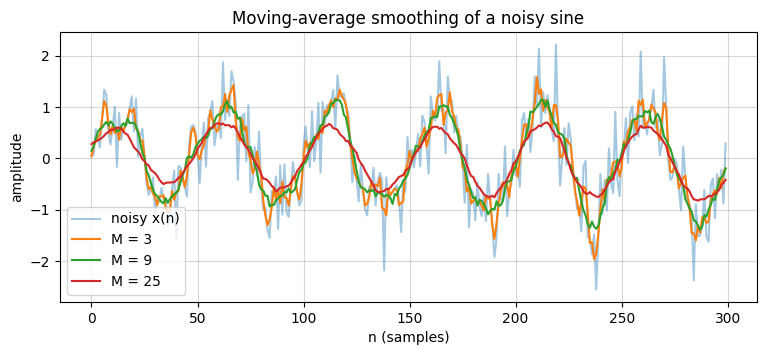

In [9]:
n = np.arange(300)
rng = np.random.default_rng(0)
x = np.sin(2*np.pi*n/50) + 0.5*rng.standard_normal(300)   # sine + noise

plt.plot(n, x, alpha=0.4, label="noisy x(n)")
for M in [3, 9, 25]:
    h = np.ones(M)/M                          # moving-average filter
    y = np.convolve(x, h, mode="same")
    plt.plot(n, y, label=f"M = {M}")
plt.title("Moving-average smoothing of a noisy sine")
plt.xlabel("n (samples)"); plt.ylabel("amplitude")
plt.legend(); plt.show()

### Observations (Task 3.2)

A longer moving average removes more noise but distorts the signal.
M = 3 leaves a lot of noise. M = 9 removes most of the noise with only a
small loss in the sine's height. M = 25 is very smooth, but the sine's
amplitude shrinks a lot, because the averaging window is about half of one
period (50 samples) and starts to average away the signal itself. The ends
of the signal are also distorted because of zero padding. So there is a
trade-off: more noise reduction against more distortion.

## Task 3.3: Testing linearity and time-invariance

In [10]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]     # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]  # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


### Observations (Task 3.3)

- x^2: not linear, because squaring a sum creates a cross term 2ab x1 x2,
  so superposition fails. It is time-invariant, because a delayed input
  gives a delayed output.
- n x(n): linear, but not time-invariant, because the gain n changes with
  time, so a delayed input does not give a delayed output.
- Moving average: both linear and time-invariant, so it is an LTI system.

## Task 3.4: Finding a hidden delay with cross-correlation

noise std = 0.5: estimated delay = 37 samples
noise std = 1: estimated delay = 37 samples
noise std = 2: estimated delay = 37 samples
noise std = 4: estimated delay = 87 samples


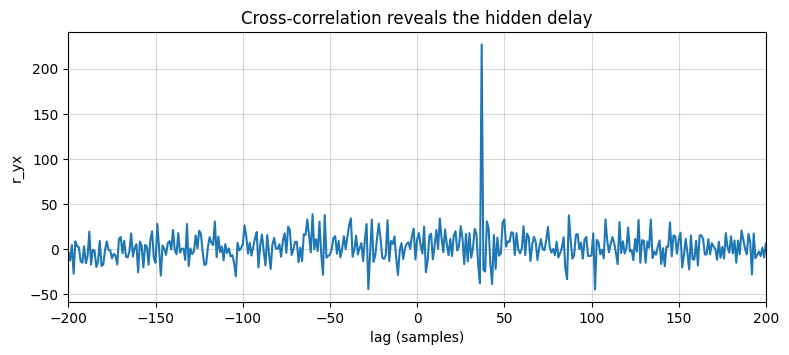

delay = 37.0 ms,  distance = 12.69 m


In [11]:
fs = 1000
true_delay = 37

for sigma in [0.5, 1, 2, 4]:
    rng = np.random.default_rng(1)
    x = rng.standard_normal(500)
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    print(f"noise std = {sigma}: estimated delay = {lags[np.argmax(r)]} samples")

# plot the low-noise case as evidence
sigma = 0.5
rng = np.random.default_rng(1)
x = rng.standard_normal(500)
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
plt.plot(lags, r); plt.xlim(-200, 200)
plt.title("Cross-correlation reveals the hidden delay")
plt.xlabel("lag (samples)"); plt.ylabel("r_yx")
plt.show()

d = true_delay/fs
print("delay =", d*1000, "ms,  distance =", round(d*343, 2), "m")

### Observations (Task 3.4)

The cross-correlation peaks at lag 37 samples, which is 37 ms at fs = 1000 Hz.
The estimate was correct for noise std = ... and failed at noise std = ...
(or: stayed correct up to 4). Distance = 0.037 s x 343 m/s = 12.7 m.

## Task 3.5: Difference equation

recursion  : [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
lfilter    : [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
closed form: [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
all match: True
final value = 5.3333  H(1) = 5.3333


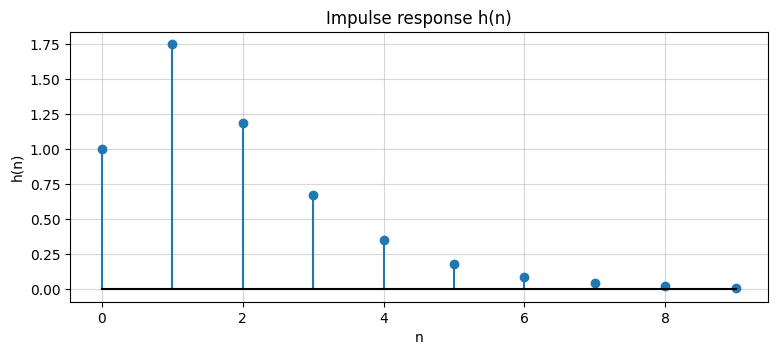

In [12]:
N = 10
imp = np.zeros(N); imp[0] = 1

h_rec = np.zeros(N)                       # 1. direct recursion
for n in range(N):
    h_rec[n] = imp[n] + (imp[n-1] if n >= 1 else 0)
    if n >= 1: h_rec[n] += 0.75*h_rec[n-1]
    if n >= 2: h_rec[n] -= 0.125*h_rec[n-2]

b, a = [1, 1], [1, -0.75, 0.125]
h_lf = signal.lfilter(b, a, imp)          # 2. lfilter
n = np.arange(N)
h_cf = 6*0.5**n - 5*0.25**n               # 3. closed form

print("recursion  :", np.round(h_rec, 4))
print("lfilter    :", np.round(h_lf, 4))
print("closed form:", np.round(h_cf, 4))
print("all match:", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_cf))

s = signal.lfilter(b, a, np.ones(200))    # 4. step response
print("final value =", round(s[-1], 4), " H(1) =", round(sum(b)/sum(a), 4))

plt.stem(n, h_lf, basefmt="k-")
plt.title("Impulse response h(n)"); plt.xlabel("n"); plt.ylabel("h(n)")
plt.show()

## Analysis questions

1. np.convolve runs in compiled code, my loop in interpreted Python, so it was [your ratio]x faster. Direct convolution needs L x M multiplications.

2. Only the moving average is LTI. x^2 is not linear (cross term 2ab x1 x2). n x(n) is not time-invariant (the gain depends on n). This can be predicted from the definitions.

3. (i) Locating leaks in water pipes from the delay between two sensors. (ii) Radar ranging at airports.

4. IIR (feedback, h(n) never becomes exactly zero). Stable: the poles 0.5 and 0.25 are inside the unit circle and h(n) decays, so the sum of |h(n)| is finite (about 5.33).